In [1]:
import os, json, time, warnings, datetime
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import skew

from sklearn.model_selection import TimeSeriesSplit, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, FunctionTransformer
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, HistGradientBoostingRegressor, HistGradientBoostingClassifier, IsolationForest
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, roc_curve, ConfusionMatrixDisplay, confusion_matrix)

warnings.filterwarnings("ignore"); SEED = 42; np.random.seed(SEED)
sns.set_theme(style="whitegrid"); pd.set_option("display.max_columns", 60)

In [2]:
# ==========================================
# LOAD EXISTING DATASET AND DICTIONARY
# ==========================================

import pandas as pd

# Load weather dataset
data = pd.read_csv("weather_daily_combined.csv")

# Restore datetime datatype
data["date"] = pd.to_datetime(data["date"])

# Create working dataframe
df = data.copy().sort_values(["city", "date"]).reset_index(drop=True)

# Date features
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day

# Season feature
def season(month, lat):
    if lat < 0:
        month = (month + 5) % 12 + 1

    if month in (12, 1, 2):
        return "Winter"
    elif month in (3, 4, 5):
        return "Spring"
    elif month in (6, 7, 8):
        return "Summer"
    else:
        return "Autumn"

df["season"] = [
    season(m, lat)
    for m, lat in zip(df["month"], df["latitude"])
]

# Load dictionary if available
try:
    dictionary = pd.read_csv("data_dictionary.csv")
    print("Data dictionary loaded.")
except FileNotFoundError:
    dictionary = None
    print("data_dictionary.csv not found.")

print("\nDataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

data_dictionary.csv not found.

Dataset loaded successfully!
Shape: (54795, 26)


,city,country,latitude,longitude,date,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,sunshine_duration,daylight_duration,relative_humidity_2m_mean,dew_point_2m_mean,cloud_cover_mean,pressure_msl_mean,year,month,day,season
0,Beijing,China,39.9042,116.4074,2016-01-01,0,-0.9,5.2,-5.5,0.0,0.0,0.0,9.8,16.2,83,8.85,32070.03,33806.85,69,-6.2,1,1023.7,2016,1,1,Winter
1,Beijing,China,39.9042,116.4074,2016-01-02,1,0.4,7.7,-5.1,0.0,0.0,0.0,6.6,13.3,26,8.89,32120.31,33848.43,64,-6.2,10,1020.2,2016,1,2,Winter
2,Beijing,China,39.9042,116.4074,2016-01-03,2,-1.3,3.7,-4.5,0.0,0.0,0.0,9.9,17.3,121,8.87,32172.32,33893.72,74,-5.5,10,1023.0,2016,1,3,Winter
3,Beijing,China,39.9042,116.4074,2016-01-04,3,-2.2,2.2,-5.7,0.0,0.0,0.0,12.4,29.2,9,8.15,32225.93,33942.63,42,-14.2,30,1030.0,2016,1,4,Winter
4,Beijing,China,39.9042,116.4074,2016-01-05,0,-4.1,1.3,-7.2,0.0,0.0,0.0,8.7,20.5,321,9.50,32281.02,33995.07,36,-17.4,0,1030.3,2016,1,5,Winter


In [4]:


CITIES = [  # city, country, lat, lon
    ("Islamabad", "Pakistan", 33.6844, 73.0479), ("Karachi", "Pakistan", 24.8607, 67.0011),
    ("New York", "United States", 40.7128, -74.0060), ("Los Angeles", "United States", 34.0522, -118.2437),
    ("Mexico City", "Mexico", 19.4326, -99.1332), ("Sao Paulo", "Brazil", -23.5505, -46.6333),
    ("Buenos Aires", "Argentina", -34.6037, -58.3816), ("London", "United Kingdom", 51.5074, -0.1278),
    ("Paris", "France", 48.8566, 2.3522), ("Moscow", "Russia", 55.7558, 37.6173),
    ("Cairo", "Egypt", 30.0444, 31.2357), ("Lagos", "Nigeria", 6.5244, 3.3792),
    ("Nairobi", "Kenya", -1.2921, 36.8219), ("Cape Town", "South Africa", -33.9249, 18.4241),
    ("Dubai", "United Arab Emirates", 25.2048, 55.2708), ("Mumbai", "India", 19.0760, 72.8777),
    ("Beijing", "China", 39.9042, 116.4074), ("Tokyo", "Japan", 35.6762, 139.6503),
    ("Singapore", "Singapore", 1.3521, 103.8198), ("Sydney", "Australia", -33.8688, 151.2093),
]

DAILY = ["weather_code", "temperature_2m_mean", "temperature_2m_max", "temperature_2m_min",
         "precipitation_sum", "rain_sum", "precipitation_hours", "wind_speed_10m_max",
         "wind_gusts_10m_max", "wind_direction_10m_dominant", "shortwave_radiation_sum",
         "sunshine_duration", "daylight_duration", "relative_humidity_2m_mean",
         "dew_point_2m_mean", "cloud_cover_mean", "pressure_msl_mean"]

URL = "https://archive-api.open-meteo.com/v1/archive"

# 1. Location reference table
locations = pd.DataFrame(CITIES, columns=["city", "country", "latitude", "longitude"])
locations.to_csv("city_locations.csv", index=False)

# 2. Fetch one city (retries if rate-limited)
def fetch_city(lat, lon):
    params = {"latitude": lat, "longitude": lon,
              "start_date": "2016-01-01", "end_date": "2025-12-31",
              "daily": ",".join(DAILY), "timezone": "auto"}
    for attempt in range(4):
        r = requests.get(URL, params=params, timeout=120)
        if r.status_code == 429:           # rate limit: wait and retry
            time.sleep(60 * (attempt + 1))
            continue
        r.raise_for_status()
        return r.json()["daily"]
    raise RuntimeError("Rate limit not cleared after 4 attempts")

# 3. Fetch all cities and combine
frames, failed = [], []
for city, country, lat, lon in CITIES:
    try:
        df = pd.DataFrame(fetch_city(lat, lon)).rename(columns={"time": "date"})
        df.insert(0, "city", city)
        df.insert(1, "country", country)
        df.insert(2, "latitude", lat)
        df.insert(3, "longitude", lon)
        frames.append(df)
        print(f"{city}: {len(df)} rows")
    except Exception as e:
        failed.append(city)
        print(f"{city}: FAILED ({e})")
    time.sleep(3)

data = pd.concat(frames, ignore_index=True)
data["date"] = pd.to_datetime(data["date"])
data.to_csv("weather_daily_combined.csv", index=False)

# 4. Report what was actually returned
print("\nTotal rows:", len(data))
print("Cities retrieved:", data["city"].nunique(), "| Failed:", failed or "none")
print("Missing values per column:\n", data.isna().sum()[data.isna().sum() > 0])
data.head()

Islamabad: 3653 rows
Karachi: 3653 rows
New York: FAILED (HTTPSConnectionPool(host='archive-api.open-meteo.com', port=443): Read timed out.)
Los Angeles: 3653 rows
Mexico City: 3653 rows
Sao Paulo: 3653 rows
Buenos Aires: 3653 rows
London: 3653 rows
Paris: 3653 rows
Moscow: 3653 rows
Cairo: 3653 rows
Lagos: 3653 rows
Nairobi: FAILED (Rate limit not cleared after 4 attempts)
Cape Town: FAILED (Rate limit not cleared after 4 attempts)
Dubai: FAILED (Rate limit not cleared after 4 attempts)
Mumbai: FAILED (Rate limit not cleared after 4 attempts)
Beijing: 3653 rows
Tokyo: 3653 rows
Singapore: 3653 rows
Sydney: 3653 rows

Total rows: 54795
Cities retrieved: 15 | Failed: ['New York', 'Nairobi', 'Cape Town', 'Dubai', 'Mumbai']
Missing values per column:
 Series([], dtype: int64)


,city,country,latitude,longitude,date,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,sunshine_duration,daylight_duration,relative_humidity_2m_mean,dew_point_2m_mean,cloud_cover_mean,pressure_msl_mean
0,Islamabad,Pakistan,33.6844,73.0479,2016-01-01,3,11.3,18.8,6.2,0.0,0.0,0.0,5.9,14.0,17,11.28,31525.90,35856.37,63,3.7,50,1021.2
1,Islamabad,Pakistan,33.6844,73.0479,2016-01-02,3,10.5,18.0,4.7,0.0,0.0,0.0,8.0,15.8,4,10.62,31095.62,35889.02,68,4.3,42,1022.2
2,Islamabad,Pakistan,33.6844,73.0479,2016-01-03,3,11.7,19.5,5.4,0.0,0.0,0.0,7.6,19.4,355,11.98,32011.75,35924.56,64,4.4,66,1018.8
3,Islamabad,Pakistan,33.6844,73.0479,2016-01-04,53,12.8,16.9,9.3,3.7,3.7,11.0,10.9,23.4,48,6.67,30468.78,35962.90,75,8.5,73,1019.5
4,Islamabad,Pakistan,33.6844,73.0479,2016-01-05,3,12.1,17.9,7.5,0.0,0.0,0.0,10.2,20.9,356,12.12,34957.46,36003.99,78,8.1,44,1020.0


In [3]:
df = data.copy().sort_values(["city", "date"]).reset_index(drop=True)

# Date attributes
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day

def season(month, lat):
    if lat < 0:                          # southern hemisphere: shift seasons by 6 months
        month = (month + 5) % 12 + 1
    if month in (12, 1, 2): return "Winter"
    if month in (3, 4, 5):  return "Spring"
    if month in (6, 7, 8):  return "Summer"
    return "Autumn"

df["season"] = [season(m, lat) for m, lat in zip(df["month"], df["latitude"])]

# Data dictionary covering ALL columns
info = {  # field: (unit, meaning)
    "city": ("text", "city name"),
    "country": ("text", "country name"),
    "latitude": ("°", "city latitude"),
    "longitude": ("°", "city longitude"),
    "date": ("date", "calendar date of the observation"),
    "year": ("year", "year derived from date"),
    "month": ("1-12", "month derived from date"),
    "day": ("1-31", "day of month derived from date"),
    "season": ("text", "meteorological season (hemisphere-aware)"),
    "weather_code": ("WMO code", "most severe weather condition of the day"),
    "temperature_2m_mean": ("°C", "daily mean temperature (2 m)"),
    "temperature_2m_max": ("°C", "daily maximum temperature"),
    "temperature_2m_min": ("°C", "daily minimum temperature"),
    "precipitation_sum": ("mm", "total daily precipitation"),
    "rain_sum": ("mm", "daily rain only"),
    "precipitation_hours": ("hours", "hours with precipitation"),
    "wind_speed_10m_max": ("km/h", "maximum wind speed (10 m)"),
    "wind_gusts_10m_max": ("km/h", "maximum wind gust (10 m)"),
    "wind_direction_10m_dominant": ("°", "dominant wind direction"),
    "shortwave_radiation_sum": ("MJ/m²", "daily solar radiation sum"),
    "sunshine_duration": ("seconds", "daily sunshine duration"),
    "daylight_duration": ("seconds", "daily daylight duration"),
    "relative_humidity_2m_mean": ("%", "mean relative humidity"),
    "dew_point_2m_mean": ("°C", "mean dew point"),
    "cloud_cover_mean": ("%", "mean cloud cover"),
    "pressure_msl_mean": ("hPa", "mean sea-level pressure"),
}

dictionary = pd.DataFrame(
    [(f, unit, meaning, str(df[f].dtype)) for f, (unit, meaning) in info.items()],
    columns=["field", "unit", "meaning", "dtype"])
dictionary.to_csv("data_dictionary.csv", index=False)
display(dictionary)

,field,unit,meaning,dtype
0,city,text,city name,str
1,country,text,country name,str
2,latitude,°,city latitude,float64
3,longitude,°,city longitude,float64
4,date,date,calendar date of the observation,datetime64[us]
5,year,year,year derived from date,int32
6,month,1-12,month derived from date,int32
7,day,1-31,day of month derived from date,int32
8,season,text,meteorological season (hemisphere-aware),str
9,weather_code,WMO code,most severe weather condition of the day,int64


In [4]:
print(f" Shape : {df.shape}")
print("first 5")
display(df.head())
print("last 5")
display(df.tail())
print(df.columns.tolist())
print(f" column names : {df.columns}")
print(f" data information : {df.info()}")
print(f" not null data : {df.count()}")
print(f" data types : {df.dtypes}")
print(f" descriptive data : {df.describe().T}")
print(f"memory usage : {df.memory_usage(deep=True)}")


cat_col = ["city","country","season"]
for col in cat_col:
    print(f"{col.upper()}")
    print(df[col].unique())
    print(f"number of unique values : {df[col].nunique()}")
    
for col in cat_col:
    print(f"Frequency distribution for {col}")
    print(df[col].value_counts())

print("Missing values per column:")
print(df.isnull().sum())

print("Total missing values:", df.isnull().sum().sum())

print("Missing values by city:")
print(df.groupby("city").apply(lambda x: x.isnull().sum().sum()))

print("Missing values by date:")
print(df.groupby("date").apply(lambda x: x.isnull().sum().sum()))
missing_report = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage (%)": (df.isnull().mean() * 100).round(2)
})

display(missing_report)


 Shape : (54795, 26)
first 5


,city,country,latitude,longitude,date,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,sunshine_duration,daylight_duration,relative_humidity_2m_mean,dew_point_2m_mean,cloud_cover_mean,pressure_msl_mean,year,month,day,season
0,Beijing,China,39.9042,116.4074,2016-01-01,0,-0.9,5.2,-5.5,0.0,0.0,0.0,9.8,16.2,83,8.85,32070.03,33806.85,69,-6.2,1,1023.7,2016,1,1,Winter
1,Beijing,China,39.9042,116.4074,2016-01-02,1,0.4,7.7,-5.1,0.0,0.0,0.0,6.6,13.3,26,8.89,32120.31,33848.43,64,-6.2,10,1020.2,2016,1,2,Winter
2,Beijing,China,39.9042,116.4074,2016-01-03,2,-1.3,3.7,-4.5,0.0,0.0,0.0,9.9,17.3,121,8.87,32172.32,33893.72,74,-5.5,10,1023.0,2016,1,3,Winter
3,Beijing,China,39.9042,116.4074,2016-01-04,3,-2.2,2.2,-5.7,0.0,0.0,0.0,12.4,29.2,9,8.15,32225.93,33942.63,42,-14.2,30,1030.0,2016,1,4,Winter
4,Beijing,China,39.9042,116.4074,2016-01-05,0,-4.1,1.3,-7.2,0.0,0.0,0.0,8.7,20.5,321,9.50,32281.02,33995.07,36,-17.4,0,1030.3,2016,1,5,Winter


last 5


,city,country,latitude,longitude,date,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,sunshine_duration,daylight_duration,relative_humidity_2m_mean,dew_point_2m_mean,cloud_cover_mean,pressure_msl_mean,year,month,day,season
54790,Tokyo,Japan,35.6762,139.6503,2025-12-27,3,2.5,5.4,0.4,0.0,0.0,0.0,14.2,37.4,329,5.75,24738.86,35113.63,58,-5.3,41,1018.5,2025,12,27,Winter
54791,Tokyo,Japan,35.6762,139.6503,2025-12-28,1,3.6,9.2,-0.4,0.0,0.0,0.0,9.8,21.6,322,10.77,33110.94,35132.87,66,-2.4,2,1021.1,2025,12,28,Winter
54792,Tokyo,Japan,35.6762,139.6503,2025-12-29,3,5.2,10.4,1.7,0.0,0.0,0.0,9.2,19.4,332,10.31,32761.91,35155.24,78,1.6,17,1019.7,2025,12,29,Winter
54793,Tokyo,Japan,35.6762,139.6503,2025-12-30,3,7.2,13.8,0.9,0.0,0.0,0.0,12.4,26.3,343,10.50,32740.43,35180.74,76,2.8,16,1013.9,2025,12,30,Winter
54794,Tokyo,Japan,35.6762,139.6503,2025-12-31,3,6.9,12.1,2.2,0.0,0.0,0.0,10.3,22.7,325,10.17,32718.35,35209.35,70,1.5,35,1011.9,2025,12,31,Winter


['city', 'country', 'latitude', 'longitude', 'date', 'weather_code', 'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'precipitation_sum', 'rain_sum', 'precipitation_hours', 'wind_speed_10m_max', 'wind_gusts_10m_max', 'wind_direction_10m_dominant', 'shortwave_radiation_sum', 'sunshine_duration', 'daylight_duration', 'relative_humidity_2m_mean', 'dew_point_2m_mean', 'cloud_cover_mean', 'pressure_msl_mean', 'year', 'month', 'day', 'season']
 column names : Index(['city', 'country', 'latitude', 'longitude', 'date', 'weather_code',
       'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min',
       'precipitation_sum', 'rain_sum', 'precipitation_hours',
       'wind_speed_10m_max', 'wind_gusts_10m_max',
       'wind_direction_10m_dominant', 'shortwave_radiation_sum',
       'sunshine_duration', 'daylight_duration', 'relative_humidity_2m_mean',
       'dew_point_2m_mean', 'cloud_cover_mean', 'pressure_msl_mean', 'year',
       'month', 'day', 'season'],
      

,Missing Values,Percentage (%)
city,0,0.0
country,0,0.0
latitude,0,0.0
longitude,0,0.0
date,0,0.0
weather_code,0,0.0
temperature_2m_mean,0,0.0
temperature_2m_max,0,0.0
temperature_2m_min,0,0.0
precipitation_sum,0,0.0


In [5]:
print("Exact duplicate rows:", df.duplicated().sum())
city_date_dups = df.duplicated(subset=["city", "date"]).sum()
print("Duplicate city-date records:", city_date_dups)
bad_temp = df[df["temperature_2m_max"] <df["temperature_2m_min"]]
print("Temperature inconsistencies:", len(bad_temp))
display(bad_temp.head())
bad_humidity = df[(df["relative_humidity_2m_mean"] < 0) |(df["relative_humidity_2m_mean"] > 100)]
print("Invalid humidity values:", len(bad_humidity))
bad_cloud = df[ (df["cloud_cover_mean"] < 0) |(df["cloud_cover_mean"] > 100)]
print("Invalid cloud cover values:", len(bad_cloud))
bad_rain = df[ df["rain_sum"] < 0]
print("Negative rainfall records:", len(bad_rain))
for city in df["city"].unique():
    city_data = df[df["city"] == city].sort_values("date")
    gaps = city_data["date"].diff().dt.days
    missing_days = gaps[gaps > 1]
    if len(missing_days) > 0:
        print(f"{city} has date gaps")
city_country = df.groupby("city")["country"].nunique()
print(city_country[city_country > 1])
#i still have to do the copying and 5% error management

df_missing = df.copy()
missing_cols = [
    "temperature_2m_mean",
    "temperature_2m_max",
    "cloud_cover_mean",
    "pressure_msl_mean"
]
np.random.seed(42)
for col in missing_cols:
    rows = df_missing.sample(frac=0.05).index
    df_missing.loc[rows, col] = np.nan
missing_report = pd.DataFrame({ "Missing Count": df_missing.isnull().sum(),"Missing %": (df_missing.isnull().mean() * 100).round(2)})
display(missing_report[missing_report["Missing Count"] > 0])
missing_before = df_missing.isnull().sum()
imputer = SimpleImputer(strategy="median")
df_imputed = df_missing.copy()
df_imputed[missing_cols] = imputer.fit_transform(df_imputed[missing_cols])
comparison = pd.DataFrame({"Before": missing_before,"After": df_imputed.isnull().sum()})
display(comparison[comparison["Before"] > 0])

print("5-B")
encoded_df = pd.get_dummies(df,columns=["city", "country", "season"],drop_first=True)
print(encoded_df.shape)
display(encoded_df.head())
num_cols = ["temperature_2m_mean","temperature_2m_max","temperature_2m_min","precipitation_sum","wind_speed_10m_max"]
minmax = MinMaxScaler()
df_minmax = df.copy()
df_minmax[num_cols] = minmax.fit_transform(df_minmax[num_cols])
display(df_minmax[num_cols].head())

scaler = StandardScaler()
df_standard = df.copy()
df_standard[num_cols] = scaler.fit_transform(df_standard[num_cols])
display(df_standard[num_cols].head())

Exact duplicate rows: 0
Duplicate city-date records: 0
Temperature inconsistencies: 0


,city,country,latitude,longitude,date,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,sunshine_duration,daylight_duration,relative_humidity_2m_mean,dew_point_2m_mean,cloud_cover_mean,pressure_msl_mean,year,month,day,season


Invalid humidity values: 0
Invalid cloud cover values: 0
Negative rainfall records: 0
Series([], Name: country, dtype: int64)


,Missing Count,Missing %
temperature_2m_mean,2740,5.0
temperature_2m_max,2740,5.0
cloud_cover_mean,2740,5.0
pressure_msl_mean,2740,5.0


,Before,After
temperature_2m_mean,2740,0
temperature_2m_max,2740,0
cloud_cover_mean,2740,0
pressure_msl_mean,2740,0


5-B
(54795, 53)


,latitude,longitude,date,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,sunshine_duration,daylight_duration,relative_humidity_2m_mean,dew_point_2m_mean,cloud_cover_mean,pressure_msl_mean,year,month,day,city_Buenos Aires,city_Cairo,city_Islamabad,city_Karachi,city_Lagos,city_London,city_Los Angeles,city_Mexico City,city_Moscow,city_Paris,city_Sao Paulo,city_Singapore,city_Sydney,city_Tokyo,country_Australia,country_Brazil,country_China,country_Egypt,country_France,country_Japan,country_Mexico,country_Nigeria,country_Pakistan,country_Russia,country_Singapore,country_United Kingdom,country_United States,season_Spring,season_Summer,season_Winter
0,39.9042,116.4074,2016-01-01,0,-0.9,5.2,-5.5,0.0,0.0,0.0,9.8,16.2,83,8.85,32070.03,33806.85,69,-6.2,1,1023.7,2016,1,1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True
1,39.9042,116.4074,2016-01-02,1,0.4,7.7,-5.1,0.0,0.0,0.0,6.6,13.3,26,8.89,32120.31,33848.43,64,-6.2,10,1020.2,2016,1,2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True
2,39.9042,116.4074,2016-01-03,2,-1.3,3.7,-4.5,0.0,0.0,0.0,9.9,17.3,121,8.87,32172.32,33893.72,74,-5.5,10,1023.0,2016,1,3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True
3,39.9042,116.4074,2016-01-04,3,-2.2,2.2,-5.7,0.0,0.0,0.0,12.4,29.2,9,8.15,32225.93,33942.63,42,-14.2,30,1030.0,2016,1,4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True
4,39.9042,116.4074,2016-01-05,0,-4.1,1.3,-7.2,0.0,0.0,0.0,8.7,20.5,321,9.50,32281.02,33995.07,36,-17.4,0,1030.3,2016,1,5,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True


,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,wind_speed_10m_max
0,0.417549,0.432507,0.412903,0.0,0.069189
1,0.437216,0.466942,0.419355,0.0,0.034595
2,0.411498,0.411846,0.429032,0.0,0.070270
3,0.397882,0.391185,0.409677,0.0,0.097297
4,0.369138,0.378788,0.385484,0.0,0.057297


,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,wind_speed_10m_max
0,-2.246017,-2.000861,-2.238136,-0.386607,-1.237608
1,-2.093661,-1.720963,-2.192254,-0.386607,-1.682844
2,-2.292896,-2.168799,-2.123431,-0.386607,-1.223695
3,-2.398373,-2.336738,-2.261077,-0.386607,-0.875854
4,-2.621047,-2.437501,-2.433134,-0.386607,-1.390658


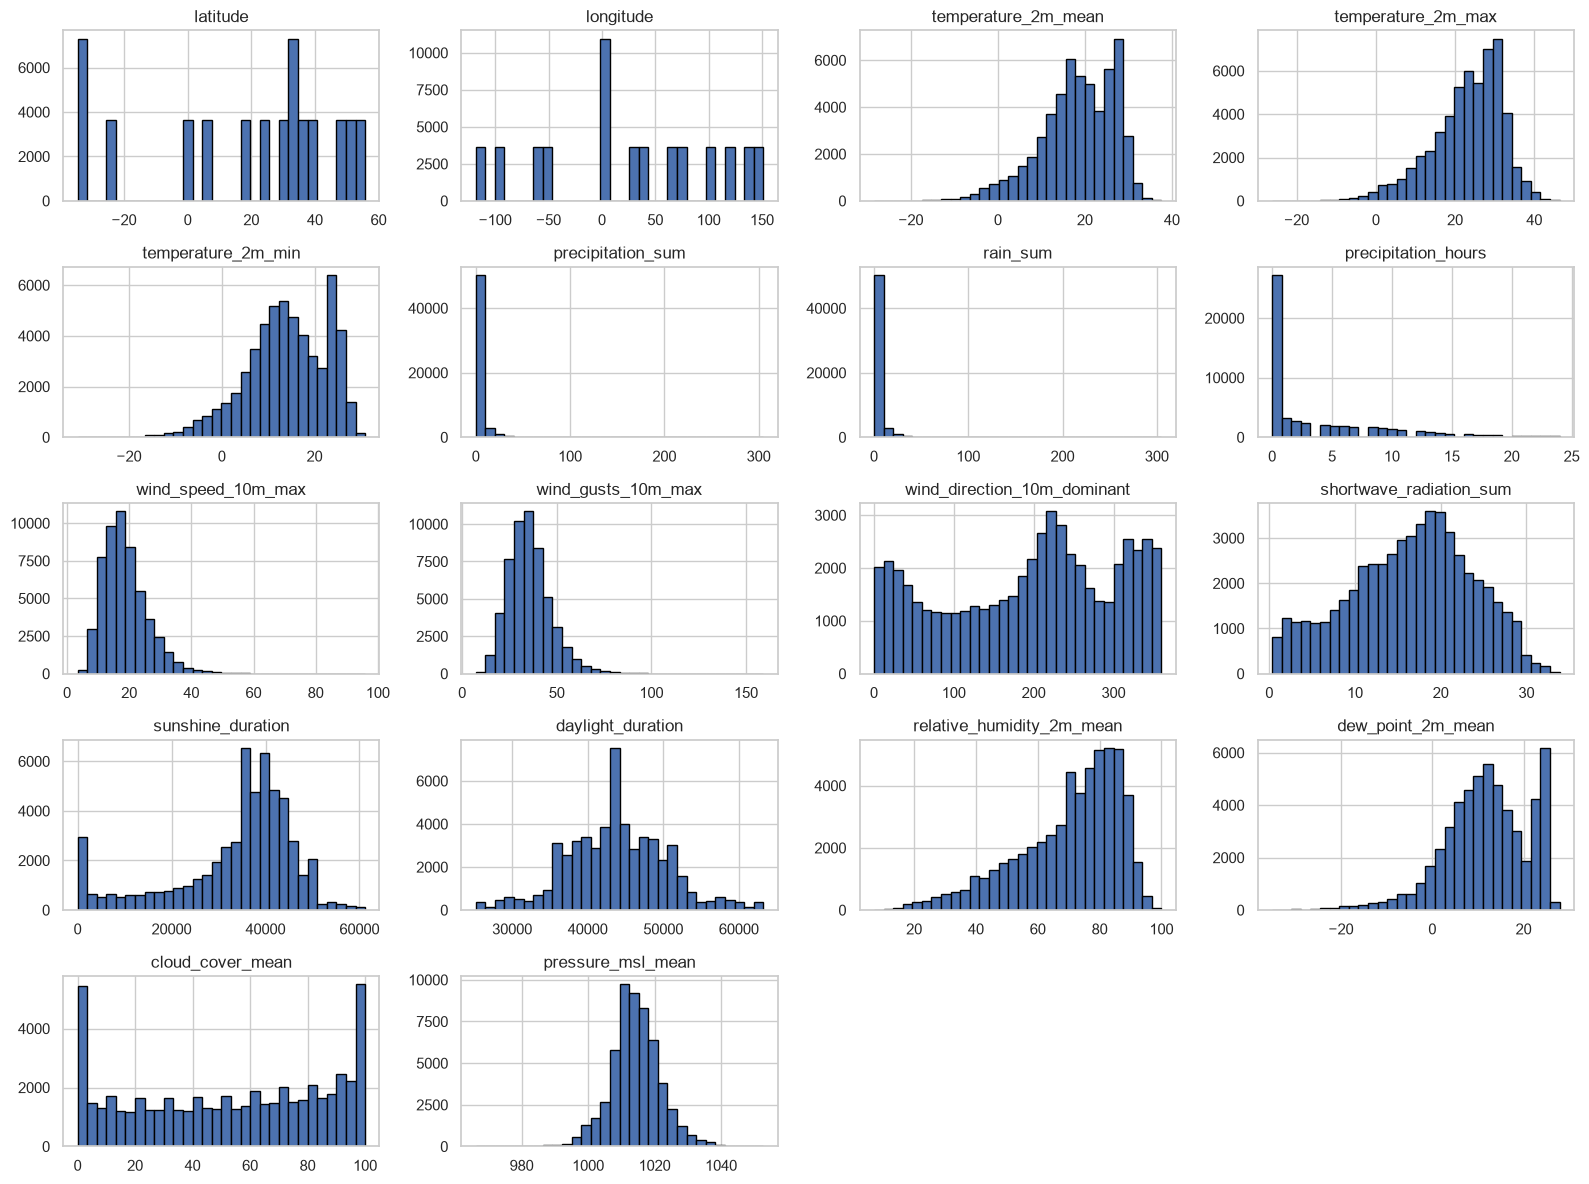

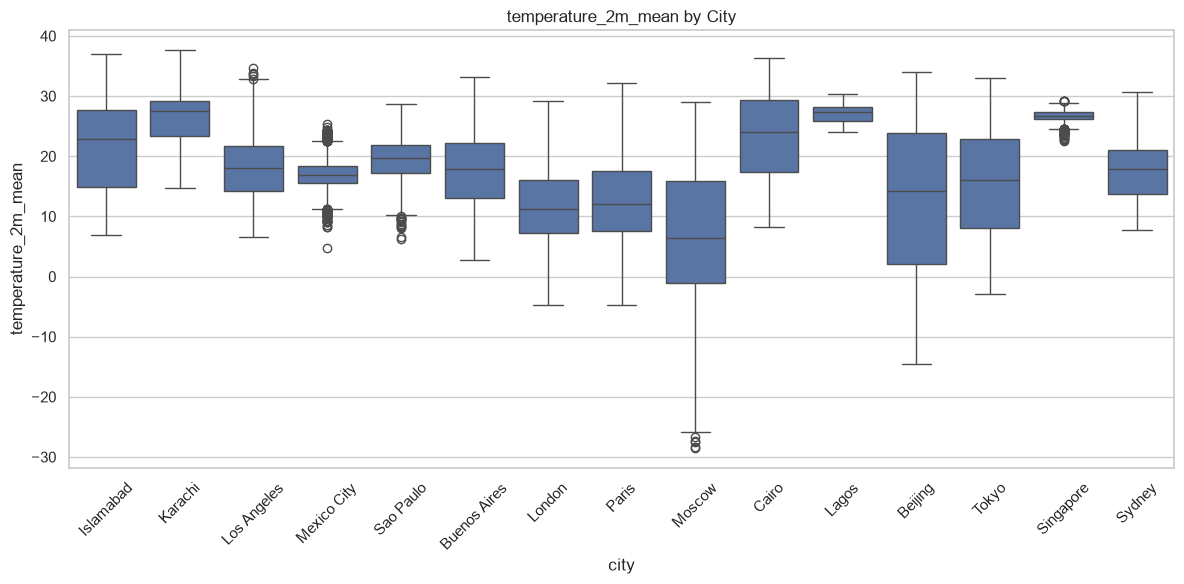

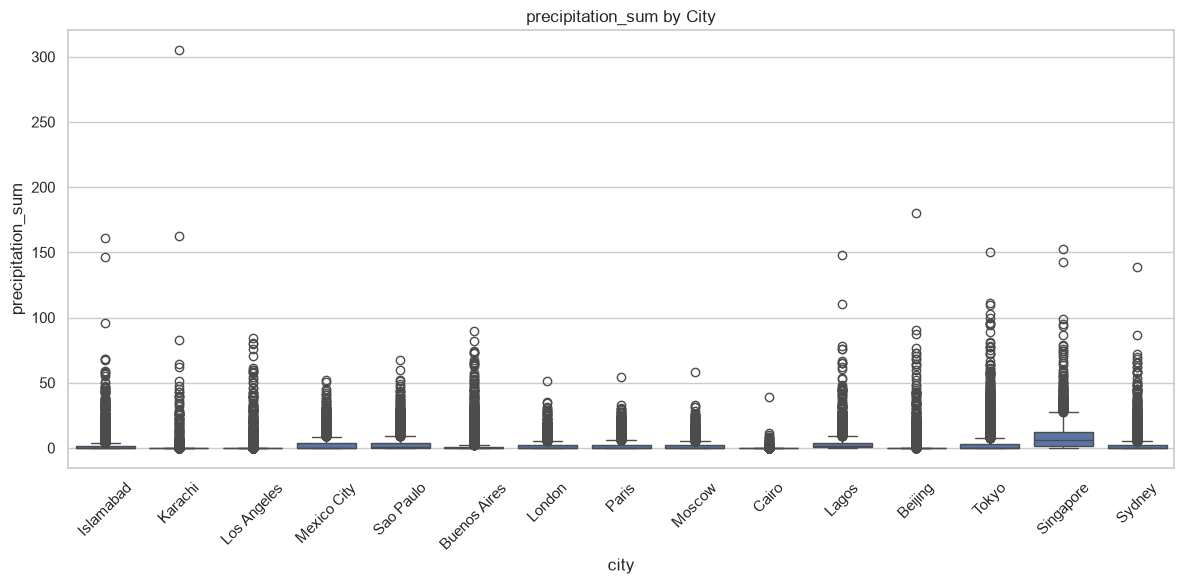

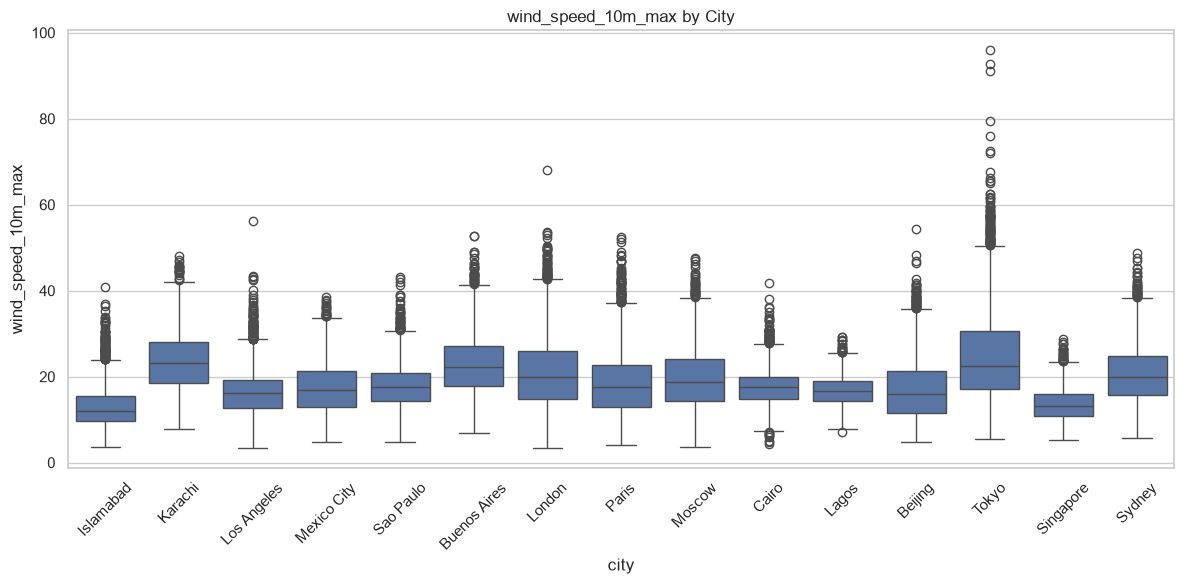

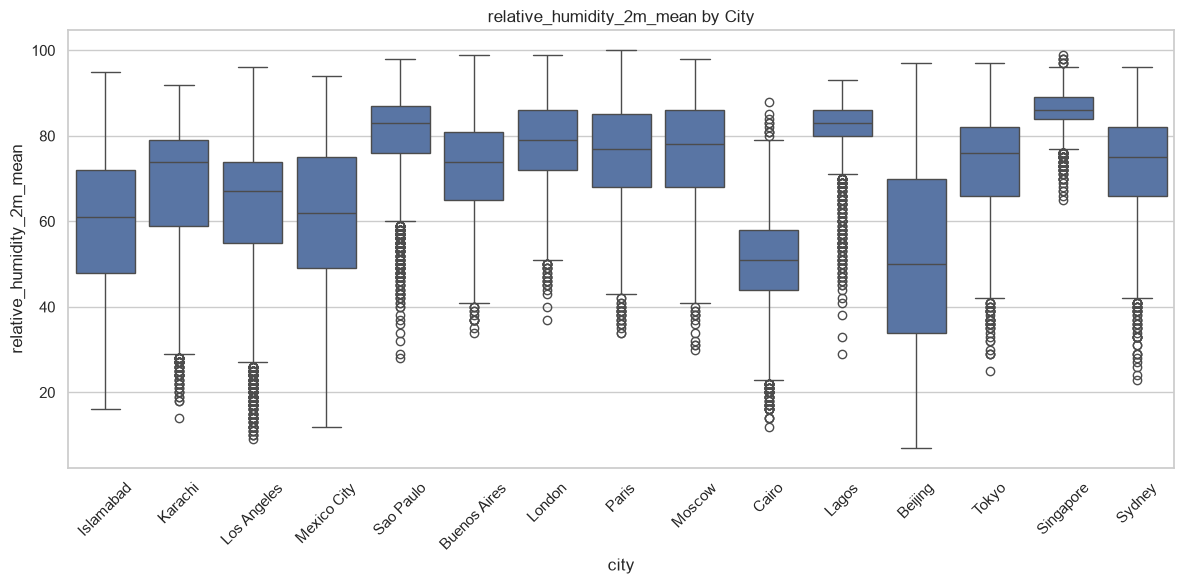

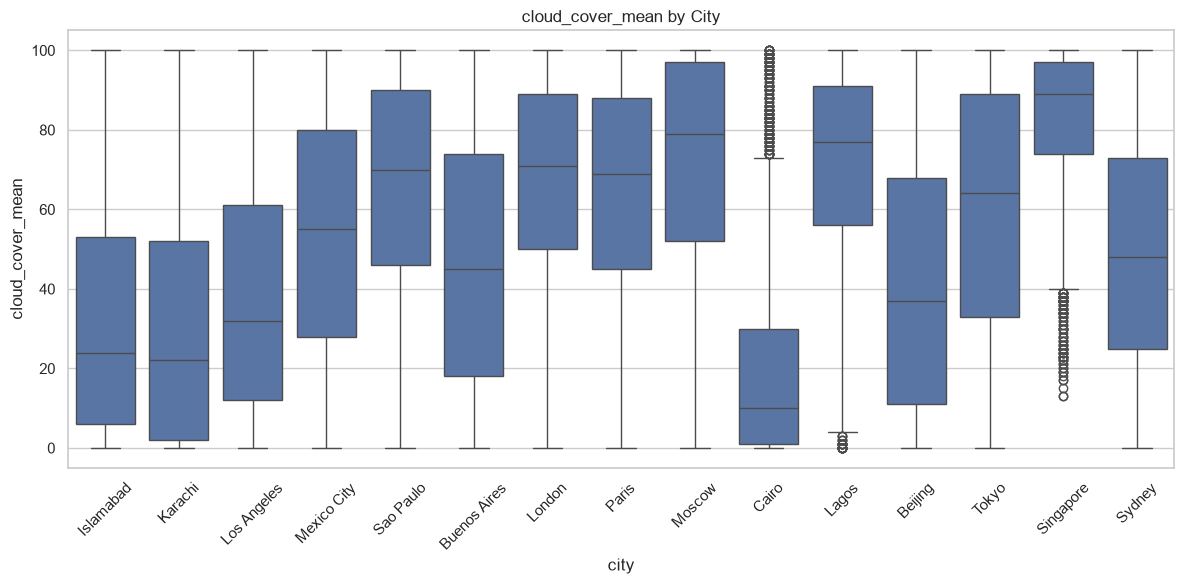

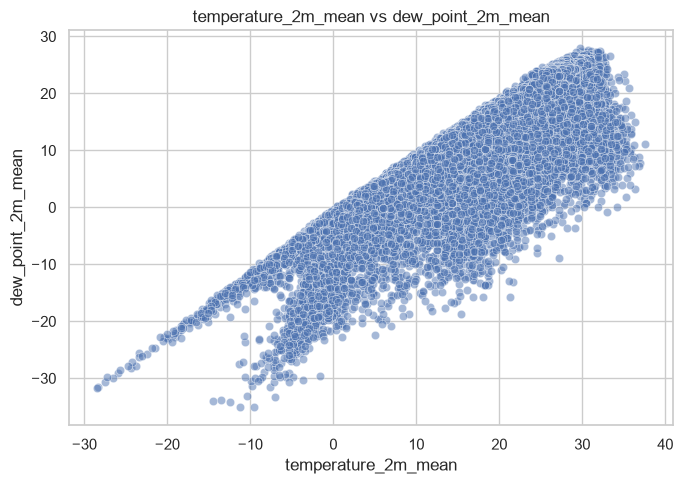

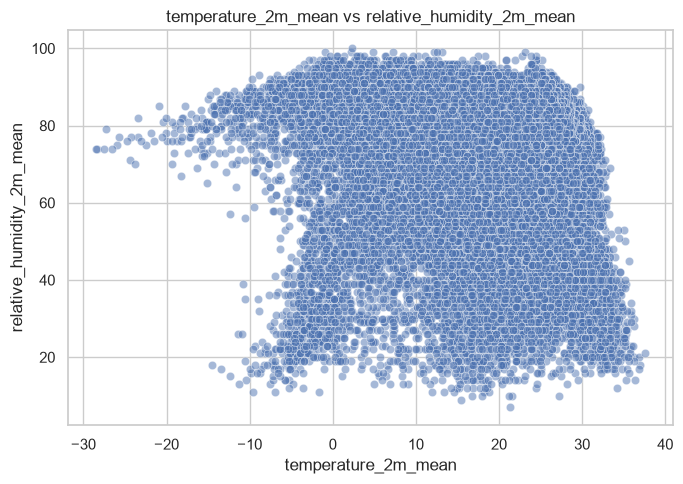

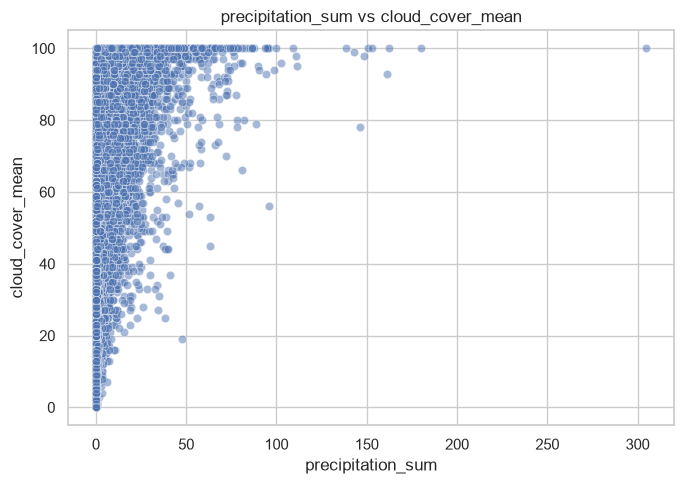

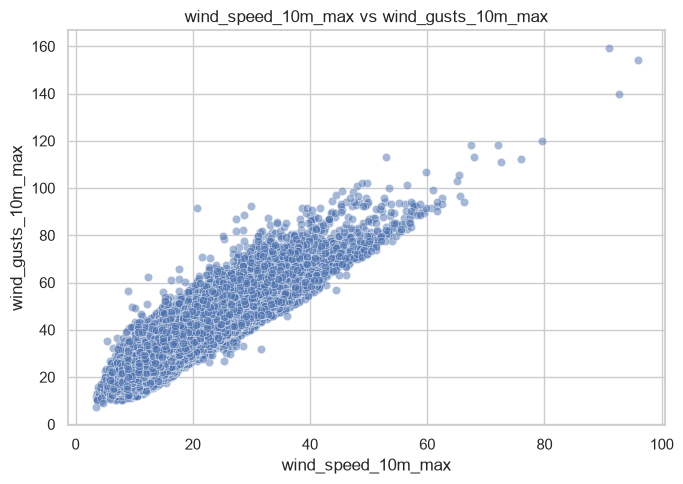

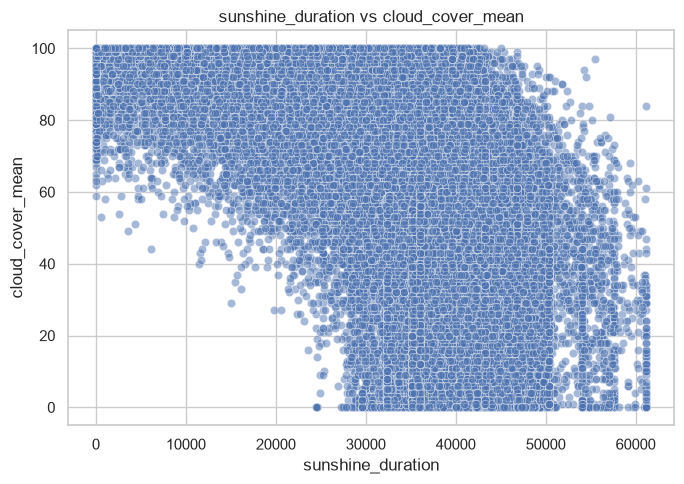

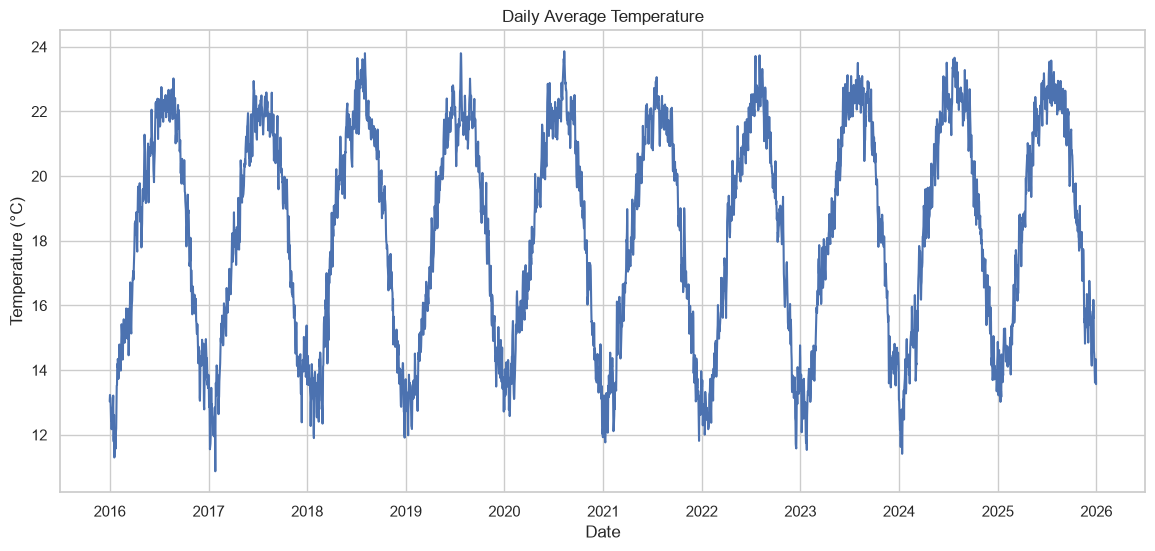

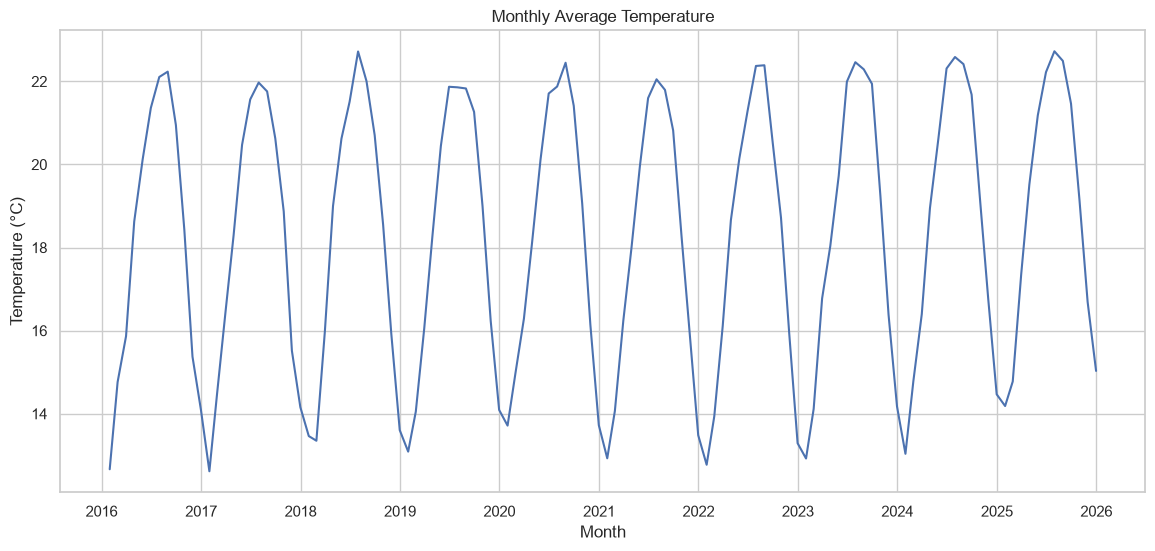

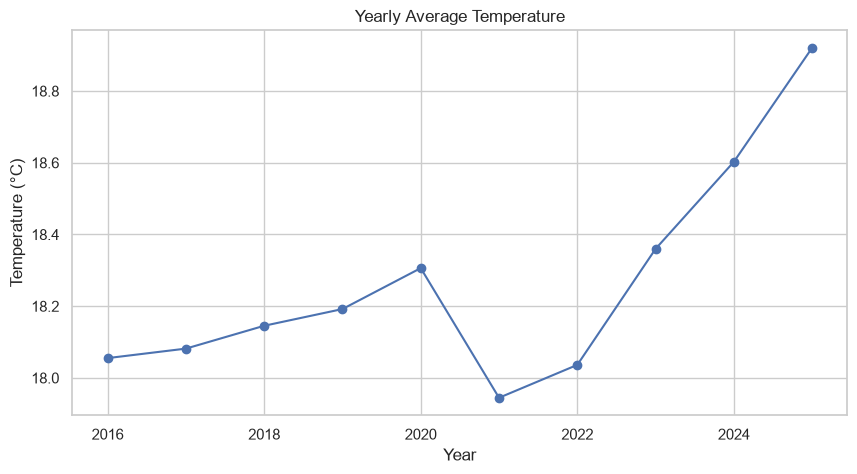

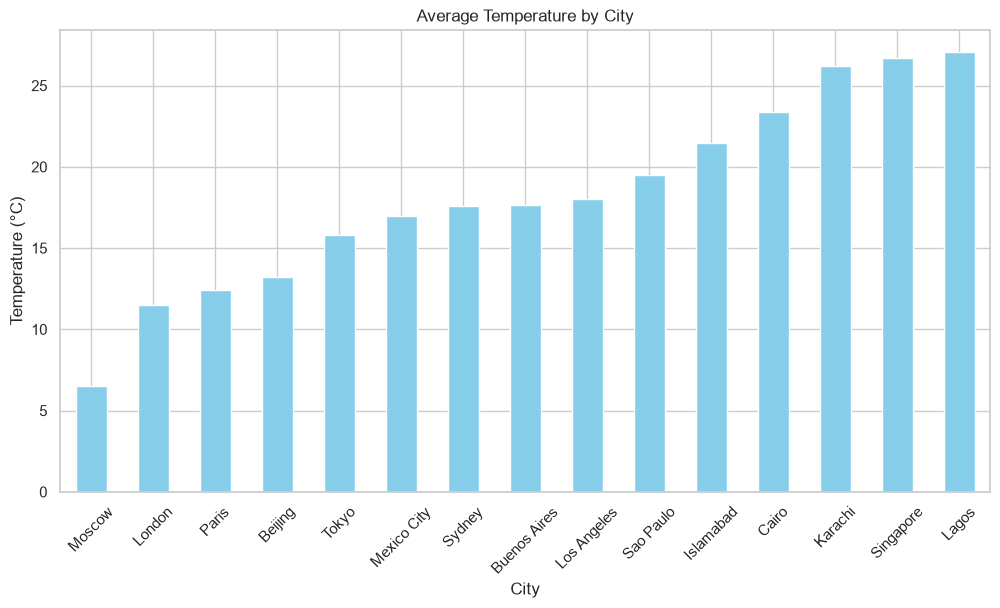

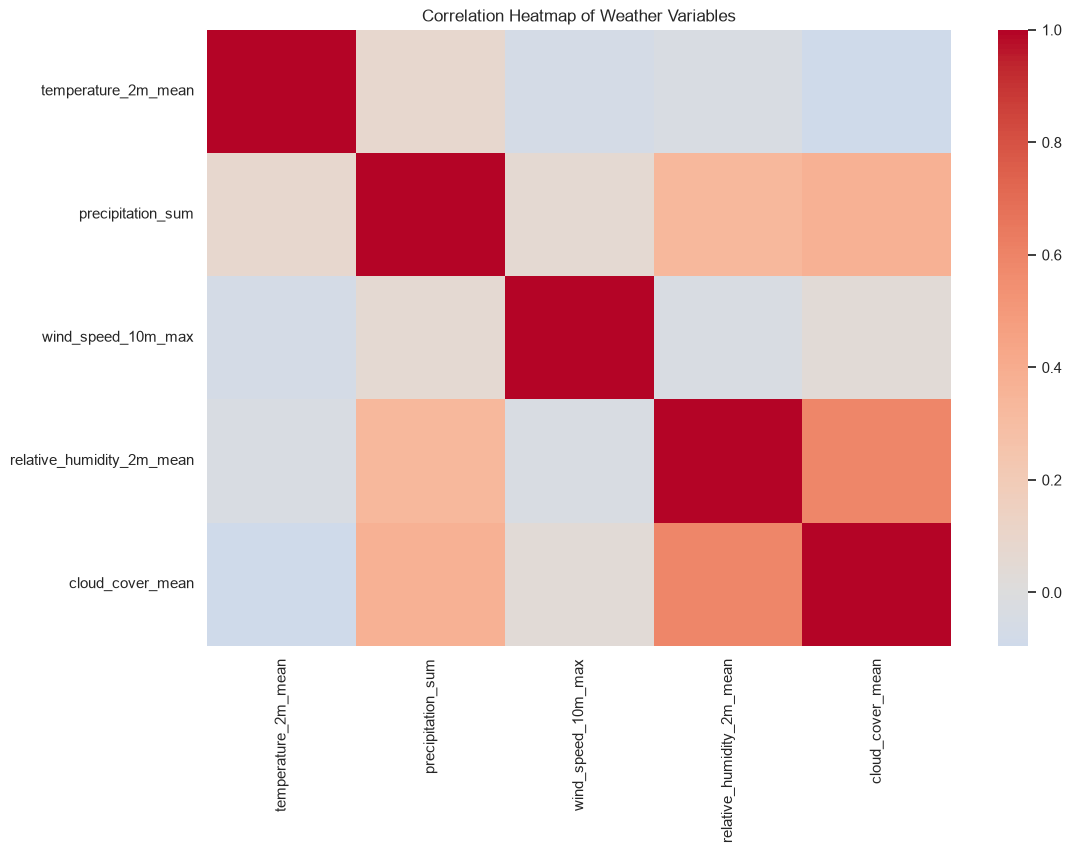

In [6]:
numerical_cols = [
    "latitude",
    "longitude",
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "precipitation_sum",
    "rain_sum",
    "precipitation_hours",
    "wind_speed_10m_max",
    "wind_gusts_10m_max",
    "wind_direction_10m_dominant",
    "shortwave_radiation_sum",
    "sunshine_duration",
    "daylight_duration",
    "relative_humidity_2m_mean",
    "dew_point_2m_mean",
    "cloud_cover_mean",
    "pressure_msl_mean"
]
df[numerical_cols].hist(bins=30,figsize=(16,12),edgecolor="black")
plt.tight_layout()
plt.show()


weather_vars = [
    "temperature_2m_mean",
    "precipitation_sum",
    "wind_speed_10m_max",
    "relative_humidity_2m_mean",
    "cloud_cover_mean"]
for var in weather_vars:
    plt.figure(figsize=(12,6))
    sns.boxplot(data=data,x="city",y=var)
    plt.xticks(rotation=45)
    plt.title(f"{var} by City")
    plt.tight_layout()
    plt.show()

pairs = [
    ("temperature_2m_mean", "dew_point_2m_mean"),
    ("temperature_2m_mean", "relative_humidity_2m_mean"),
    ("precipitation_sum", "cloud_cover_mean"),
    ("wind_speed_10m_max", "wind_gusts_10m_max"),
    ("sunshine_duration", "cloud_cover_mean")
]

for x, y in pairs:
    plt.figure(figsize=(7,5))
    sns.scatterplot(data=data,x=x,y=y,alpha=0.5)
    plt.title(f"{x} vs {y}")
    plt.tight_layout()
    plt.show()



daily_temp = data.groupby("date")["temperature_2m_mean"].mean()
plt.figure(figsize=(14,6))
plt.plot(daily_temp.index, daily_temp.values)
plt.title("Daily Average Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.show()

monthly = (data.groupby(pd.Grouper(key="date", freq="ME"))["temperature_2m_mean"].mean())
plt.figure(figsize=(14,6))
plt.plot(monthly.index, monthly.values)
plt.title("Monthly Average Temperature")
plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.show()


yearly = (data.groupby(pd.Grouper(key="date", freq="YE"))["temperature_2m_mean"].mean())
plt.figure(figsize=(10,5))
plt.plot(yearly.index.year,yearly.values,marker="o")
plt.title("Yearly Average Temperature")
plt.xlabel("Year")
plt.ylabel("Temperature (°C)")
plt.show()




avg_temp = (data.groupby("city")["temperature_2m_mean"].mean().sort_values())
plt.figure(figsize=(12,6))
avg_temp.plot( kind="bar",color="skyblue")
plt.title("Average Temperature by City")
plt.xlabel("City")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.show()


plt.figure(figsize=(12,8))
sns.heatmap(data[weather_vars].corr(),cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Weather Variables")
plt.show()



,Skewness,Type
sunshine_duration,-1.127,Highly negative
relative_humidity_2m_mean,-0.933,Moderately negative
temperature_2m_max,-0.849,Moderately negative
temperature_2m_mean,-0.778,Moderately negative
dew_point_2m_mean,-0.682,Moderately negative
temperature_2m_min,-0.570,Moderately negative
shortwave_radiation_sum,-0.229,Approximately symmetric
cloud_cover_mean,-0.152,Approximately symmetric
daylight_duration,0.078,Approximately symmetric
pressure_msl_mean,0.081,Approximately symmetric


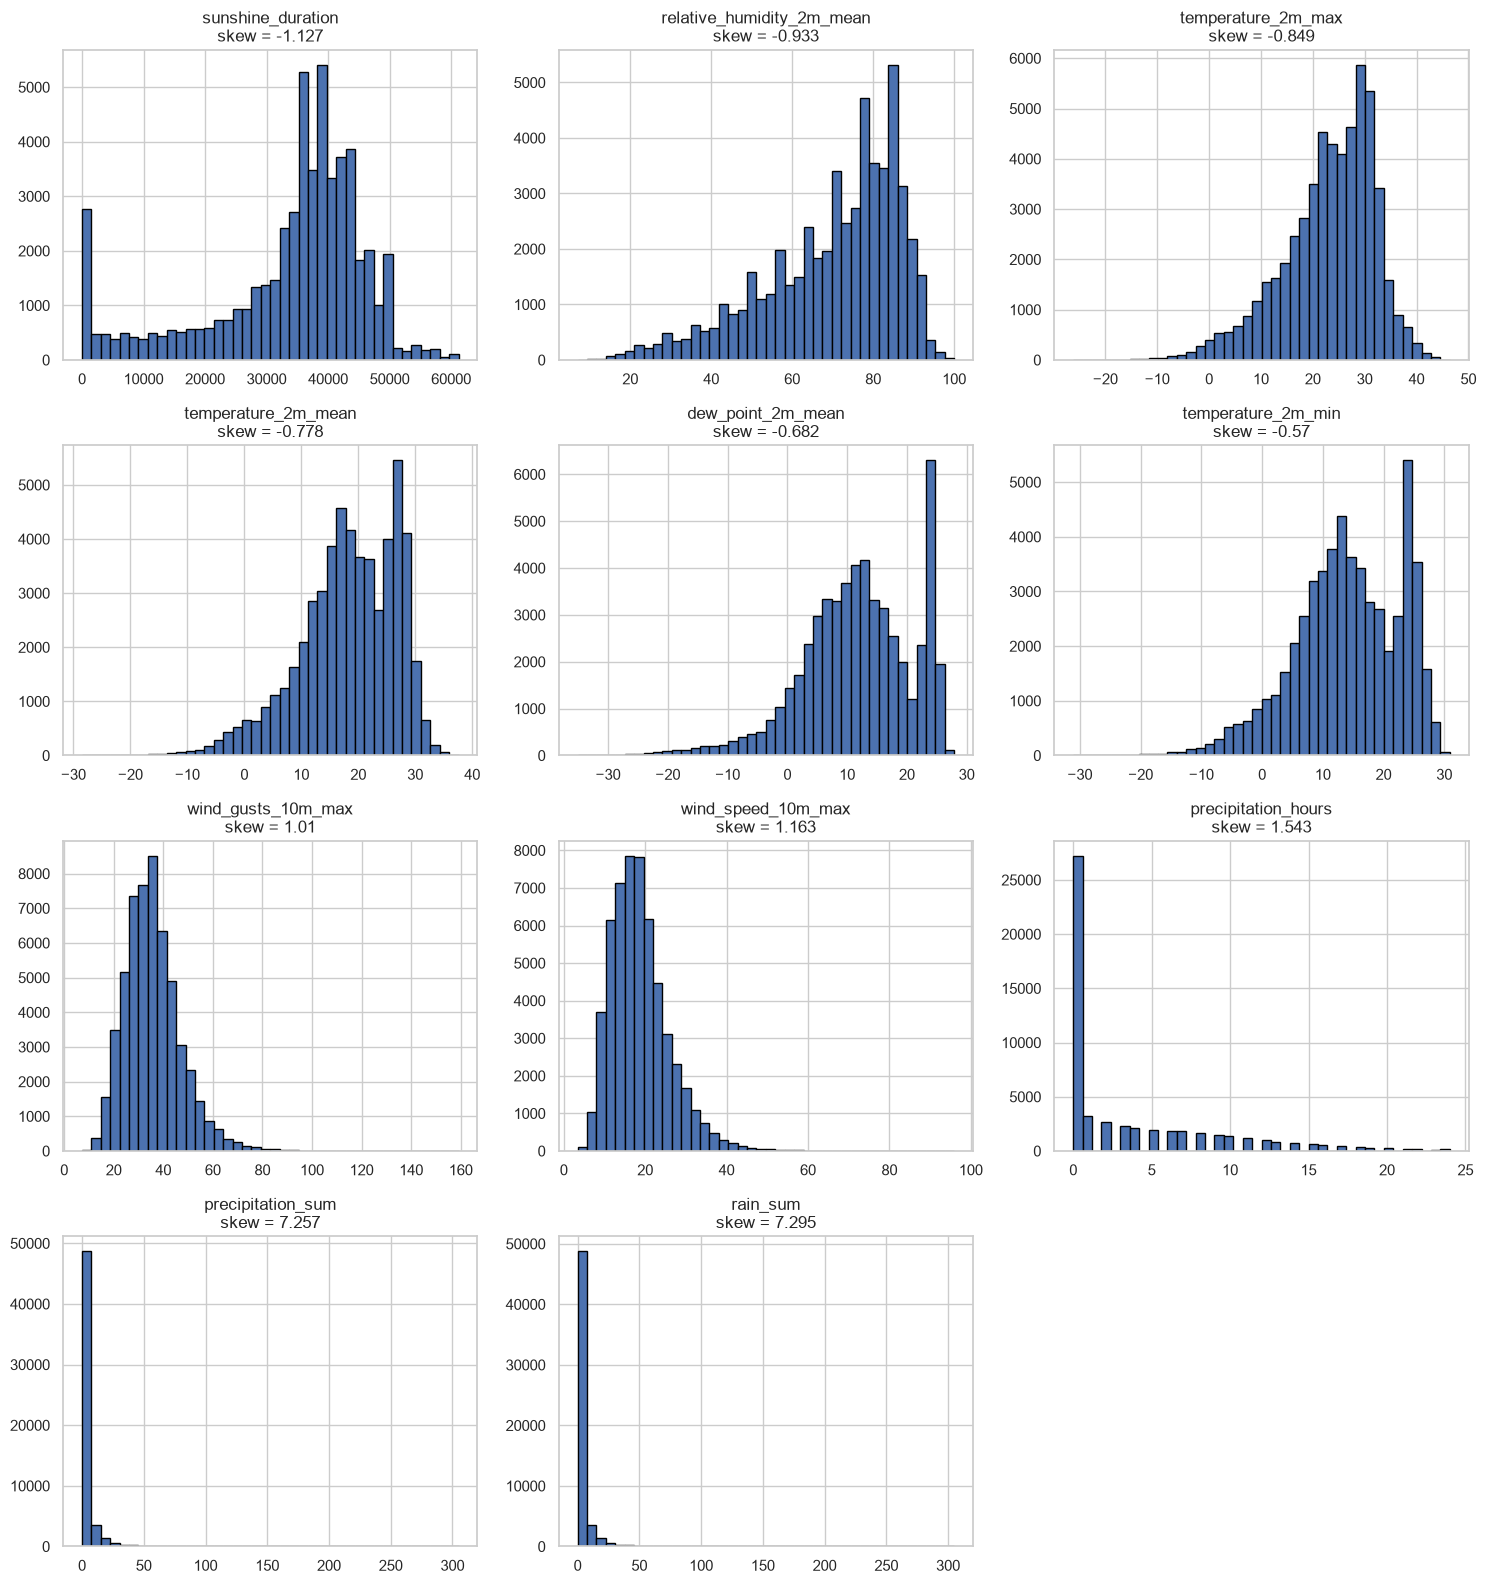

In [9]:
skew_cols = [c for c in numerical_cols if c not in ["latitude", "longitude", "wind_direction_10m_dominant"]]

skew_before = df[skew_cols].apply(lambda s: skew(s.dropna())).round(3)

def skew_label(v):
    if v > 1:
        return "Highly positive"
    if v > 0.5:  
        return "Moderately positive"
    if v < -1:  
        return "Highly negative"
    if v < -0.5: 
        return "Moderately negative"
    return "Approximately symmetric"

skew_table = pd.DataFrame({
    "Skewness": skew_before,
    "Type": skew_before.apply(skew_label)
}).sort_values("Skewness")
display(skew_table)

# histograms
skewed = skew_table[skew_table["Skewness"].abs() > 0.5].index.tolist()
fig, axes = plt.subplots(int(np.ceil(len(skewed) / 3)), 3, figsize=(15, 4 * np.ceil(len(skewed) / 3)))
for ax, col in zip(axes.ravel(), skewed):
    ax.hist(df[col], bins=40, edgecolor="black")
    ax.set_title(f"{col}\nskew = {skew_before[col]}")
for ax in axes.ravel()[len(skewed):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [10]:
to_transform = skew_table[skew_table["Skewness"] > 1].index.tolist()
to_transform = [c for c in to_transform if df[c].min() >= 0]
df_skew = df.copy()
for col in to_transform:
    df_skew[col + "_log"] = np.log1p(df_skew[col])

skew_after = pd.Series({c: skew(df_skew[c + "_log"].dropna()) for c in to_transform}).round(3)

comparison = pd.DataFrame({
    "Skew before": skew_before[to_transform],
    "Skew after (log1p)": skew_after,
})
comparison["Improved?"] = comparison["Skew after (log1p)"].abs() < comparison["Skew before"].abs()
display(comparison)

,Skew before,Skew after (log1p),Improved?
wind_gusts_10m_max,1.010,-0.134,True
wind_speed_10m_max,1.163,-0.015,True
precipitation_hours,1.543,0.524,True
precipitation_sum,7.257,1.422,True
rain_sum,7.295,1.458,True


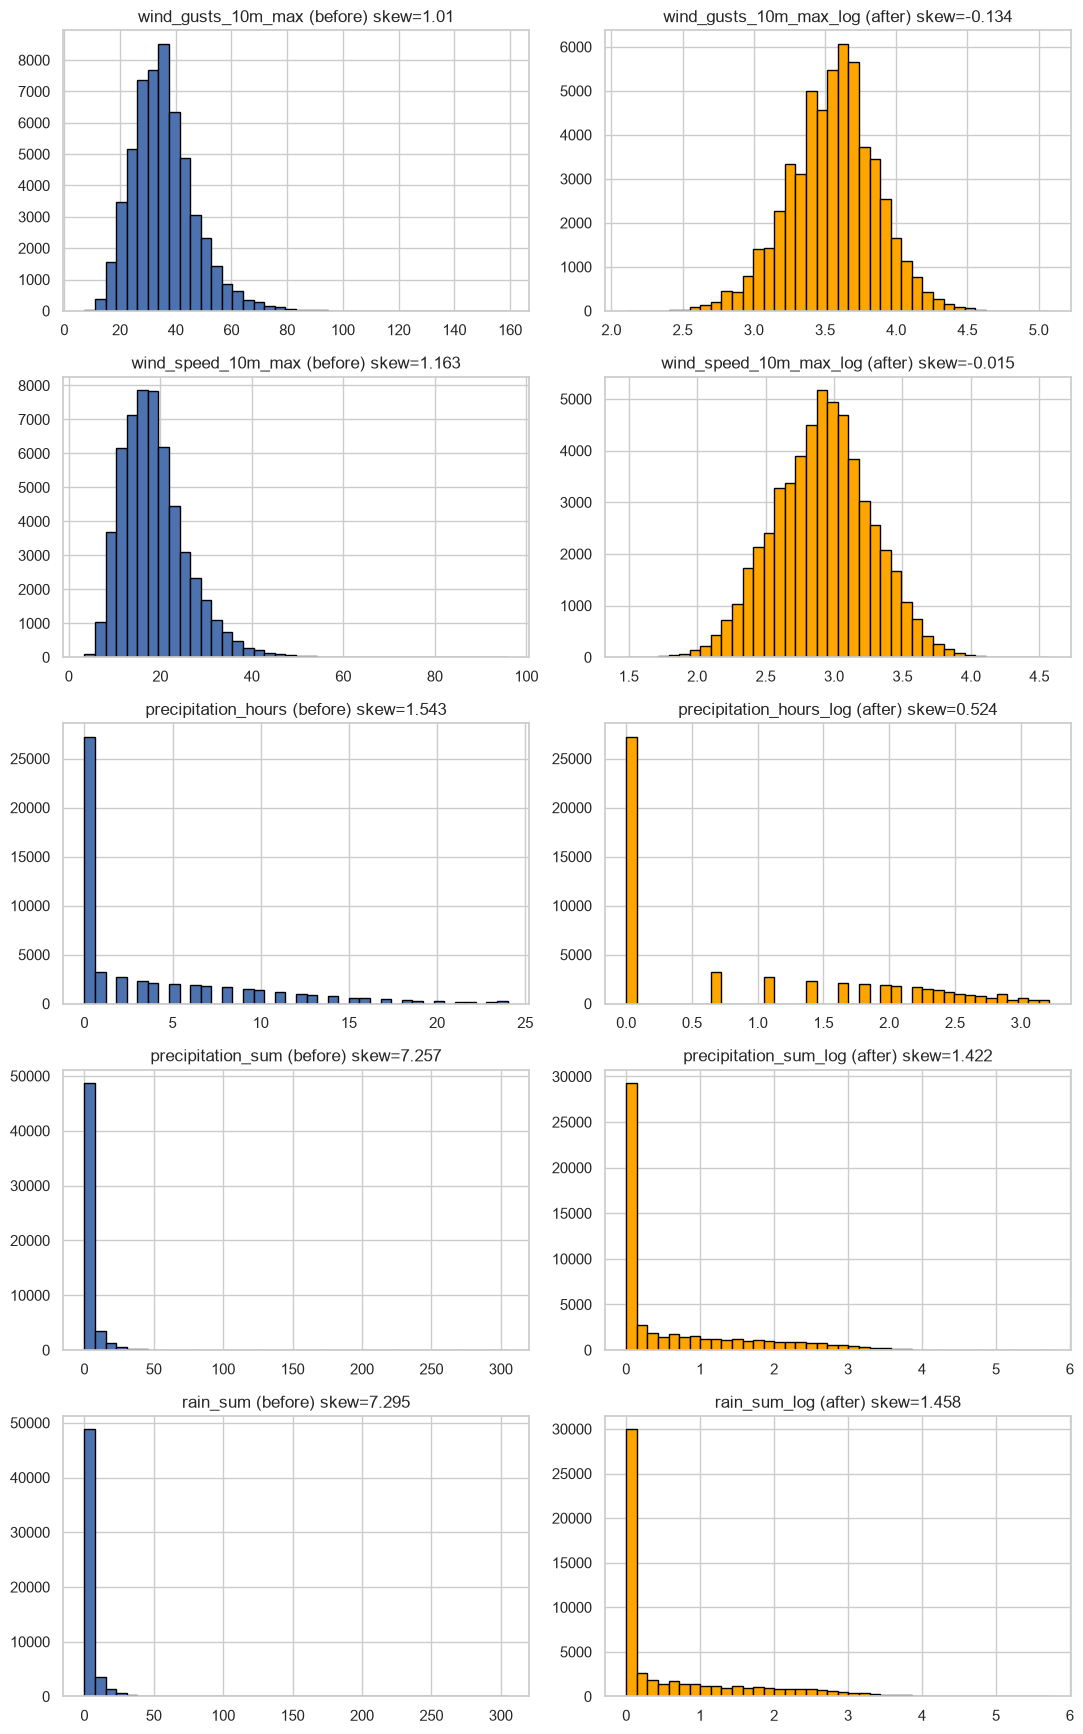

In [11]:
fig, axes = plt.subplots(len(to_transform), 2, figsize=(11, 3.5 * len(to_transform)))
axes = np.atleast_2d(axes)
for i, col in enumerate(to_transform):
    axes[i, 0].hist(df[col], bins=40, edgecolor="black")
    axes[i, 0].set_title(f"{col} (before) skew={skew_before[col]}")
    axes[i, 1].hist(df_skew[col + "_log"], bins=40, edgecolor="black", color="orange")
    axes[i, 1].set_title(f"{col}_log (after) skew={skew_after[col]}")
plt.tight_layout()
plt.show()